# Support vector machines

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://githubtocolab.com/EnriqueVilchezL/machine-learning/blob/main/book/03-supervised/svm/svm-notebook.ipynb)

Companion notebook for the *Support vector machines* slides. Each idea is written first by
hand with NumPy and then with the scikit-learn tool that does the same job.

**Data:** two species of the Iris flowers (setosa and versicolor) on two petal measurements,
and the Breast Cancer Wisconsin data for the kernel comparison.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn import svm
from sklearn.datasets import load_breast_cancer, load_iris
from sklearn.metrics import hinge_loss
from sklearn.metrics.pairwise import rbf_kernel
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
GAMMA = 0.5
LARGE_C = 1000
SOFT_C = 0.1
LEARNING_RATE = 0.1
STEPS = 5000
TOLERANCE = 0.01

iris = load_iris()
two_species = iris.target < 2
X = iris.data[two_species][:, 2:]          # petal length and width
y = np.where(iris.target[two_species] == 1, 1, -1)

## 1. The decision rule

A linear SVM predicts $\hat{y} = \operatorname{sign}(\mathbf{w}^\top\mathbf{x} + b)$.
After training, scikit-learn stores $\mathbf{w}$ in `coef_` and $b$ in `intercept_`.

In [2]:
model = svm.SVC(kernel="linear", C=LARGE_C).fit(X, y)
w, b = model.coef_[0], model.intercept_[0]

scores_by_hand = X @ w + b
print("same scores:", np.allclose(scores_by_hand, model.decision_function(X)))
print("same predictions:", np.array_equal(np.sign(scores_by_hand), model.predict(X)))

same scores: True
same predictions: True


## 2. The margin

The street between the classes has width $2/\lVert\mathbf{w}\rVert$. The points on its edges are the support vectors.

margin width 1.304, support vectors: 2


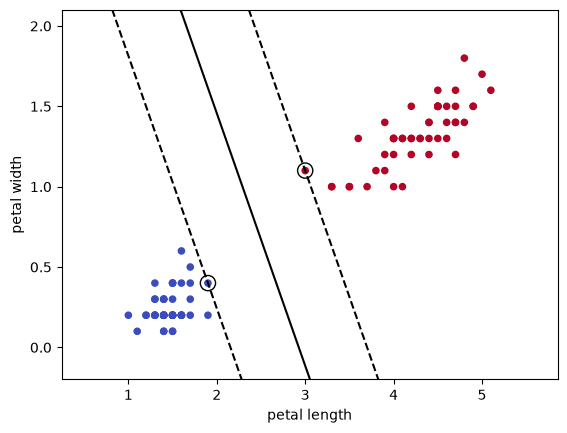

In [3]:
print(f"margin width {2 / np.linalg.norm(w):.3f}, support vectors: {len(model.support_vectors_)}")

grid = np.linspace(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5, 100)
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", s=20)
for offset, style in [(0, "-"), (-1, "--"), (1, "--")]:
    line = (offset - b - w[0] * grid) / w[1]       # solves w1 x1 + w2 x2 + b = offset for x2
    plt.plot(grid, line, "k" + style)
plt.scatter(*model.support_vectors_.T, s=120, facecolors="none", edgecolors="k")
plt.ylim(X[:, 1].min() - 0.3, X[:, 1].max() + 0.3)
plt.xlabel("petal length")
plt.ylabel("petal width")
plt.show()

## 3. The hinge loss

The soft margin pays $\max(0,\ 1 - y_i f(\mathbf{x}_i))$ for each point inside the street or on the wrong side.

In [4]:
hinge_per_point = np.maximum(0, 1 - y * scores_by_hand)     # max(0, 1 - y_i f(x_i))
hinge_by_hand = np.mean(hinge_per_point)
same_hinge = np.isclose(hinge_by_hand, hinge_loss(y, scores_by_hand))
print(f"average hinge loss {hinge_by_hand:.4f} | same result:", same_hinge)

average hinge loss 0.0000 | same result: True


## 4. Training a soft-margin SVM by hand

Training minimizes $\tfrac{1}{2}\lVert\mathbf{w}\rVert^2 + C\sum_i \max(0,\ 1 - y_i f(\mathbf{x}_i))$.
The hinge has a corner, so we take small steps against its subgradient: only the points inside the street
or on the wrong side push $\mathbf{w}$ and $b$, and the steps shrink as training goes on.

In [5]:
class LinearSVC:
    """Linear soft-margin SVM trained by subgradient descent on the hinge loss."""

    def __init__(self, C: float = 1.0, learning_rate: float = 0.1, max_iter: int = 5000):
        self.C = C
        self.learning_rate = learning_rate
        self.max_iter = max_iter

    def fit(self, X, y):
        self.coef_ = np.zeros(X.shape[1])                     # w
        self.intercept_ = 0.0                                 # b
        for step in range(1, self.max_iter + 1):
            margins = y * self.decision_function(X)           # y_i f(x_i)
            inside = margins < 1                              # points with a positive hinge
            rate = self.learning_rate / np.sqrt(step)         # steps shrink over time
            hinge_grad_w = -self.C * y[inside] @ X[inside]    # -C sum y_i x_i
            hinge_grad_b = -self.C * y[inside].sum()          # -C sum y_i
            grad_w = self.coef_ + hinge_grad_w                # w comes from (1/2)||w||^2
            self.coef_ = self.coef_ - rate * grad_w
            self.intercept_ = self.intercept_ - rate * hinge_grad_b
        return self

    def decision_function(self, X):
        return X @ self.coef_ + self.intercept_

    def predict(self, X):
        return np.sign(self.decision_function(X))

    def score(self, X, y):
        return np.mean(self.predict(X) == y)


by_hand = LinearSVC(C=SOFT_C, learning_rate=LEARNING_RATE, max_iter=STEPS).fit(X, y)

scikit-learn solves the same problem exactly; the steps only get close to the answer.
So the scores are compared with a tolerance of 0.01 (`TOLERANCE`), and the predictions must match exactly.

In [6]:
classifier = svm.SVC(kernel="linear", C=SOFT_C).fit(X, y)
soft_scores_by_hand = by_hand.decision_function(X)
soft_scores_library = classifier.decision_function(X)
same_scores = np.allclose(soft_scores_by_hand, soft_scores_library, atol=TOLERANCE)
print("scores agree within tolerance:", same_scores)
print("same predictions:", np.array_equal(by_hand.predict(X), classifier.predict(X)))

scores agree within tolerance: True
same predictions: True


## 5. The RBF kernel

$K(\mathbf{x}, \mathbf{x}') = \exp(-\gamma \lVert\mathbf{x} - \mathbf{x}'\rVert^2)$ measures similarity: 1 for the same point, near 0 for far points.

In [7]:
differences = X[:, None, :] - X[None, :, :]                 # x - x' for every pair
squared_distances = (differences**2).sum(axis=2)            # ||x - x'||^2
kernel_by_hand = np.exp(-GAMMA * squared_distances)
print("same result:", np.allclose(kernel_by_hand, rbf_kernel(X, gamma=GAMMA)))

same result: True


## 6. Linear or curved boundary

On the Breast Cancer data, compare a linear SVM with an RBF SVM. Both need scaled features.

In [8]:
X_bc, y_bc = load_breast_cancer(return_X_y=True)
for kernel in ["linear", "rbf"]:
    pipeline = make_pipeline(StandardScaler(), svm.SVC(kernel=kernel))
    accuracy = cross_val_score(pipeline, X_bc, y_bc, cv=5).mean()
    print(f"{kernel:6} kernel: cross-validated accuracy {accuracy:.3f}")

linear kernel: cross-validated accuracy 0.972
rbf    kernel: cross-validated accuracy 0.974


## Exercises

1. Lower `C` in section 1 to 0.01. What happens to the margin width and the number of support vectors?
2. Compute by hand the distance $|\mathbf{w}^\top\mathbf{x} + b| / \lVert\mathbf{w}\rVert$ of every support vector to the line.
3. Try `gamma` values 0.001, 0.01 and 0.1 for the RBF SVM in section 6.